# Spectral descriptors as classifiers (Phase 3, step 6)

**Question.** Do Shape-DNA, HKS, WKS and GPS carry signal beyond volume, once measured on size-matched surfaces? Earlier steps found global eigenvalues add little, so the real test is whether anything using eigenfunctions, which see local shape, does better.

How to rerun: [`docs/reproductions/lb-descriptors.md`](../docs/reproductions/lb-descriptors.md). What each descriptor looks like: [`lb-features-3d.ipynb`](lb-features-3d.ipynb).

## 1. Theory

With $s_k=\lambda_k\text{Area}$ and $\psi_k=\phi_k\sqrt{\text{Area}}$, every summary below is scale-free and ignores pose. What each can know differs, and that matters:

| Summary | Depends on | What follows |
|---|---|---|
| Shape-DNA, $s_k$ | Eigenvalues | Isospectral surfaces look identical |
| Mean HKS over the surface | Eigenvalues | **Equals the heat trace** $Z(\tau)=\sum_ke^{-s_k\tau}$, since $\int\psi_k^2=\text{Area}$. So it adds nothing to Shape-DNA in principle |
| HKS spread, 95th percentile, maxima | Eigenfunctions too | Can separate isospectral surfaces: the Sunada pair differs here |
| Mean WKS | Nothing | **Identically 1 for every shape,** since its weights sum to 1 and $\psi_k^2$ averages 1. So it is excluded |
| WKS spread and 95th percentile | Eigenfunctions too | One frequency band at a time |
| GPS pair distances | Eigenvalues and eigenfunctions | Independent of eigenfunction signs |
| **Tips:** local maxima of HKS | Eigenfunctions too | Counts protrusions at the scale set by $\tau$. Our own summary, motivated by HKS peaking at tips |

## 2. Implementation details

| Choice | Ours | Why |
|---|---|---|
| Surface | Size-matched, as in `lb-stability.ipynb`; no topology correction | The descriptors do not need genus 0 |
| Eigenpairs | Up to 200 | Sets the shortest usable time |
| HKS times | 8, log-spaced, $\tau$ from 0.004 to 0.2 | Tail below $e^{-8}$ at the shortest |
| WKS energies | 8 of 100 points, $\log s$ from $\log 20$ to $\log 2500$ | Same bands for every lesion |
| GPS | First 20 coordinates, 20,000 area-weighted random pairs, 7 quantiles | Rustamov's distance distribution in spirit; a seeded sample |
| Noise and predicted masks | As `lb-stability.ipynb`, 2 draws | Comparable checks |
| Labels | Train+Validation only | **Test stayed clean at this step; `lb-feature-evaluation.ipynb` later used it once** |

## 3. Verification

Tests in `test/utils_tests/features_tests/test_signature.py`: rotation and scale, mean HKS against the heat trace, mean WKS, tips on a bumpy sphere, no spread on a sphere, and the Sunada pair.

## 4. Tips on shapes and real lesions

Orange points mark local maxima of HKS. At short times they catch every small feature; at longer times only the large protrusions remain. The bumpy sphere has 14 bumps.

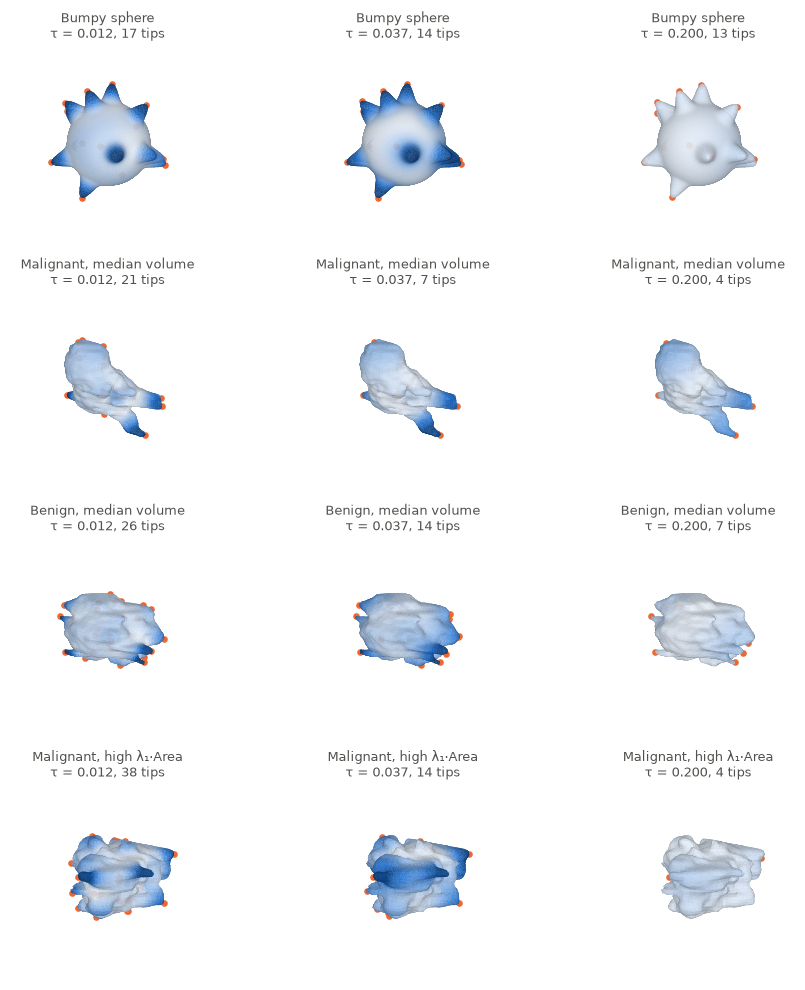

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from abus_classification.features.shape_descriptor.shape_descriptors import ENERGY_RANGE, TAUS, WAVE_PICKS, compute_eigendecomposition, compute_hks, compute_laplace_beltrami_operator, compute_wks, local_maxima
from abus_classification.utils.mesh import draw_mesh
from test.utils_tests.features_tests.test_signature import bumpy_sphere

BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
RAMP = LinearSegmentedColormap.from_list("ramp", ["#e6eef8", "#86b2e8", BLUE, "#104a8e"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
stab = np.load("../results/lb-stability/sample_meshes.npz"); round_ = np.load("../results/lb-roundness/sample_meshes.npz")
def lesion(store, key): return trimesh.Trimesh(store[key + "_vertices"].astype(float), store[key + "_faces"], process=False)
SHAPES = {"Bumpy sphere": bumpy_sphere(), "Malignant, median volume": lesion(stab, "malignant_clean"), "Benign, median volume": lesion(stab, "benign_clean"), "Malignant, high λ₁·Area": lesion(round_, "malignant_q95")}
def pairs(m, k=200):
    L, M = compute_laplace_beltrami_operator(m); lam, phi = compute_eigendecomposition(L, M, k=k); return lam * m.area, phi * np.sqrt(m.area)
PAIRS = {n: pairs(m) for n, m in SHAPES.items()}
picks = (2, 4, 7); fig = plt.figure(figsize=(9.5, 10))
for row, (name, m) in enumerate(SHAPES.items()):
    lam, phi = PAIRS[name]; heat = compute_hks(lam, phi, TAUS)
    for col, j in enumerate(picks):
        ax = fig.add_subplot(4, 3, row * 3 + col + 1, projection="3d"); h = heat[:, j]; draw_mesh(ax, m, h, RAMP, np.percentile(h, 2), max(np.percentile(h, 98), 1.3 * np.median(h)))
        tips = local_maxima(h, m); facing = np.ones(len(tips), bool); ax.scatter(*m.vertices[tips].T, color=ORANGE, s=14, depthshade=False, zorder=10)
        ax.set_title(f"{name}\nτ = {TAUS[j]:.3f}, {len(tips)} tips", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-tips.png", dpi=130); plt.show()

WKS at the band with the strongest 95th-percentile signal: a high 95th percentile means this band's vibration concentrates in small parts of the surface.

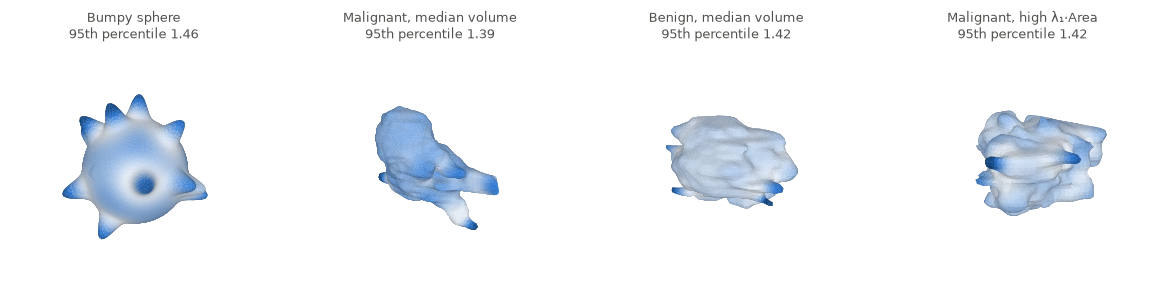

In [2]:
grid = np.linspace(np.log(ENERGY_RANGE[0]), np.log(ENERGY_RANGE[1]), 100); fig = plt.figure(figsize=(12, 3))
for i, (name, m) in enumerate(SHAPES.items()):
    lam, phi = PAIRS[name]; w = compute_wks(lam, phi, grid)[:, WAVE_PICKS[3]]; ax = fig.add_subplot(1, 4, i + 1, projection="3d"); draw_mesh(ax, m, w, RAMP, np.percentile(w, 2), np.percentile(w, 99.5))
    ax.set_title(f"{name}\n95th percentile {np.percentile(w, 95):.2f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-wks-band.png", dpi=130); plt.show()

## 5. Signal beyond volume

Train+Validation only. Five-fold CV repeated 20 times.

In [3]:
d = np.load("../results/lb-descriptors/features.npz"); R = list(map(str, d["renders"])); s = np.load("../results/lb-stability/spectra.npz")
def families(h, w, g, tp, dn):
    return {"Shape-DNA, k ≤ 20": np.log(dn[..., :20]), "Shape-DNA, k ≤ 50": np.log(dn[..., :50]), "HKS mean = heat trace": np.log(h[..., 0, :]), "HKS spread": np.log(h[..., 1, :] / h[..., 0, :]), "HKS 95th percentile": np.log(h[..., 2, :] / h[..., 0, :]),
            "WKS spread": np.log(w[..., 1, :]), "WKS 95th percentile": np.log(w[..., 2, :]), "GPS distances": np.log(g), "Tips": np.log(tp + 1.0)}
F = families(d["hks"], d["wks"], d["gps"], d["tips"], d["dna"]); tv = ~d["test"]; y = d["y"][tv]; volume = d["volume"]; v = np.log(volume[tv, 0])[:, None]
e = np.sort(s["extents"][tv, 0], -1); el = np.log(e[:, 2] / e[:, 0])[:, None]; tan = pd.read_csv("../results/lb-spectrum-content/tan_control.csv")[["SPmean", "SP90", "SP75"]].values[tv]
def oof(X, reps=20):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return np.mean([cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=i), method="decision_function") for i in range(reps)], 0)
def cv(X, reps=20):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return np.mean([roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=i), method="decision_function")) for i in range(reps)])
after = lambda X: X - LinearRegression().fit(v, X).predict(v)
rows = {n: {"Alone": cv(x[tv, 0]), "With volume": cv(np.c_[v, x[tv, 0]]), "After volume": cv(after(x[tv, 0])), "Largest |Spearman| with volume": np.abs([spearmanr(x[:, 0, i], volume[:, 0])[0] for i in range(x.shape[-1])]).max()} for n, x in F.items()}
rows["Elongation (not spectral)"] = {"Alone": cv(el), "With volume": cv(np.c_[v, el]), "After volume": cv(after(el)), "Largest |Spearman| with volume": np.nan}
rows["Control: Tan spiculation"] = {"Alone": cv(tan), "With volume": cv(np.c_[v, tan]), "After volume": cv(after(tan)), "Largest |Spearman| with volume": np.nan}
print(f"Volume alone: {cv(v):.3f}")
pd.DataFrame(rows).T.round(3)

Volume alone: 0.708


,Alone,With volume,After volume,Largest |Spearman| with volume
"Shape-DNA, k ≤ 20",0.508,0.607,0.444,0.125
"Shape-DNA, k ≤ 50",0.575,0.612,0.466,0.138
HKS mean = heat trace,0.602,0.718,0.564,0.173
HKS spread,0.608,0.713,0.571,0.121
HKS 95th percentile,0.535,0.694,0.501,0.141
WKS spread,0.569,0.702,0.516,0.128
WKS 95th percentile,0.660,0.759,0.635,0.190
GPS distances,0.541,0.696,0.483,0.185
Tips,0.675,0.766,0.638,0.334
Elongation (not spectral),0.647,0.748,0.633,NaN


### Is the gain real?

The table compares several feature families on the same 130 lesions, so the best one is favoured by chance. Two checks: a bootstrap interval on each gain in out-of-fold AUC, and a permutation test that keeps labels and volume fixed and shuffles only the new features across lesions. The permutation statistic is the **best gain over all 9 families**, which accounts for having tried them all.

In [4]:
def delta(Xa, Xb, n=4000):
    a, b = oof(Xa), oof(Xb); rng = np.random.default_rng(0); D = []
    while len(D) < n:
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(y): D.append(roc_auc_score(y[i], b[i]) - roc_auc_score(y[i], a[i]))
    lo, hi = np.percentile(D, [2.5, 97.5]); return {"AUC before": roc_auc_score(y, a), "AUC after": roc_auc_score(y, b), "Gain": roc_auc_score(y, b) - roc_auc_score(y, a), "95% CI, low": lo, "95% CI, high": hi}
tips, wave = F["Tips"][tv, 0], F["WKS 95th percentile"][tv, 0]
display(pd.DataFrame({"Volume + tips": delta(v, np.c_[v, tips]), "Volume + WKS 95th pct": delta(v, np.c_[v, wave]), "Volume + elongation": delta(v, np.c_[v, el]), "Volume, elongation + tips": delta(np.c_[v, el], np.c_[v, el, tips]), "Volume, spiculation + tips": delta(np.c_[v, tan], np.c_[v, tan, tips]), "Volume, spiculation + elongation": delta(np.c_[v, tan], np.c_[v, tan, el])}).T.round(3).style.format(precision=3).set_caption("Gain in out-of-fold AUC, Train+Validation"))
base = roc_auc_score(y, oof(v, 3)); fam = [x[tv, 0] for x in F.values()]
def best_gain(order): return max(roc_auc_score(y, oof(np.c_[v, X[order]], 3)) for X in fam) - base
observed = best_gain(np.arange(len(y))); rng = np.random.default_rng(1); null = np.array([best_gain(rng.permutation(len(y))) for _ in range(200)])
print(f"Best gain over all families: {observed:.3f}; shuffled features, 95th percentile {np.percentile(null, 95):.3f}, median {np.median(null):.3f}; permutation p = {(1 + (null >= observed).sum()) / 201:.3f}")
print("Tips AUC per time:", dict(zip(np.round(TAUS, 3), [round(roc_auc_score(y, d["tips"][tv, 0, i]), 3) for i in range(8)])))
print("Spearman of tips and elongation per time:", [round(spearmanr(tips[:, i], el[:, 0])[0], 2) for i in range(8)]); print("Median tips, malignant:", np.median(d["tips"][tv, 0][y == 1], 0), "benign:", np.median(d["tips"][tv, 0][y == 0], 0))
rf = RandomForestClassifier(300, min_samples_leaf=3, random_state=0, n_jobs=-1); X = np.c_[v, tips, wave]
print("Random forest, volume + tips + WKS 95th pct:", round(np.mean([roc_auc_score(y, cross_val_predict(rf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=i), method='predict_proba')[:, 1]) for i in range(3)]), 3))

,AUC before,AUC after,Gain,"95% CI, low","95% CI, high"
Volume + tips,0.711,0.774,0.063,-0.015,0.145
Volume + WKS 95th pct,0.711,0.765,0.054,-0.017,0.133
Volume + elongation,0.711,0.749,0.038,-0.020,0.098
"Volume, elongation + tips",0.749,0.807,0.058,-0.012,0.130
"Volume, spiculation + tips",0.802,0.817,0.015,-0.034,0.065
"Volume, spiculation + elongation",0.802,0.843,0.040,-0.000,0.085


Best gain over all families: 0.049; shuffled features, 95th percentile 0.035, median -0.001; permutation p = 0.020
Tips AUC per time: {np.float64(0.004): 0.454, np.float64(0.007): 0.56, np.float64(0.012): 0.616, np.float64(0.021): 0.653, np.float64(0.037): 0.562, np.float64(0.065): 0.628, np.float64(0.114): 0.553, np.float64(0.2): 0.489}
Spearman of tips and elongation per time: [np.float64(0.15), np.float64(0.15), np.float64(0.02), np.float64(-0.12), np.float64(-0.23), np.float64(-0.32), np.float64(-0.31), np.float64(-0.2)]
Median tips, malignant: [83. 47. 26. 16. 10.  7.  5.  4.] benign: [83. 46. 25. 14.  9.  6.  4.  4.]


Random forest, volume + tips + WKS 95th pct: 0.691


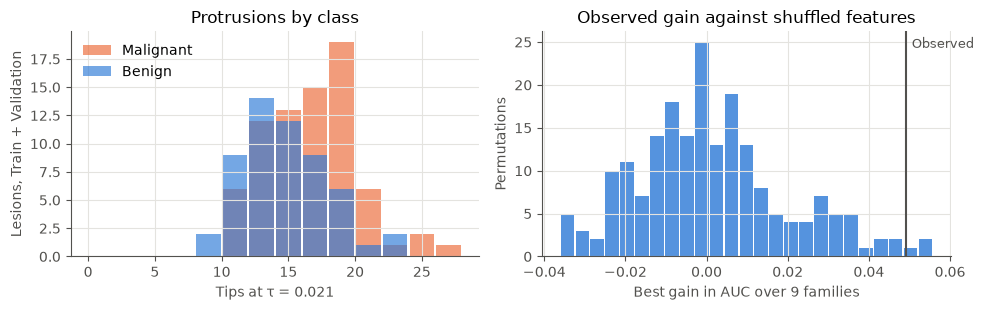

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2)); j = 3; bins = np.arange(0, d["tips"][tv, 0, j].max() + 3, 2)
ax[0].hist(d["tips"][tv, 0, j][y == 1], bins, color=ORANGE, alpha=.65, rwidth=.92, label="Malignant"); ax[0].hist(d["tips"][tv, 0, j][y == 0], bins, color=BLUE, alpha=.65, rwidth=.92, label="Benign")
ax[0].set(xlabel=f"Tips at τ = {TAUS[j]:.3f}", ylabel="Lesions, Train + Validation", title="Protrusions by class"); ax[0].legend(frameon=False)
ax[1].hist(null, 25, color=BLUE, alpha=.8, rwidth=.92); ax[1].axvline(observed, color=INK, lw=1.5); ax[1].annotate("Observed", (observed, ax[1].get_ylim()[1]), xytext=(4, -4), textcoords="offset points", va="top", color=INK, fontsize=9); ax[1].set(xlabel="Best gain in AUC over 9 families", ylabel="Permutations", title="Observed gain against shuffled features")
plt.tight_layout(); plt.savefig("../docs/assets/lb-descriptors-signal.png", dpi=150); plt.show()

## 6. Reliability

Median across each family's features.

In [6]:
def icc(x):
    ok = ~np.isnan(x).any(1); x = x[ok]; m = x.shape[1]; g = x.mean(1); b = m * g.var(ddof=1); w = ((x - g[:, None]) ** 2).sum() / (x.shape[0] * (m - 1)); return (b - w) / (b + (m - 1) * w)
I = {a: [0, R.index(f"noise {a} mm #0"), R.index(f"noise {a} mm #1")] for a in (0.25, 0.5, 1.0)}; p = np.load("../results/lb-descriptors/predicted.npz"); Fp = families(p["hks"], p["wks"], p["gps"], p["tips"], p["dna"])
print("Missing predicted surfaces per seed:", np.isnan(p["area"][:, 1:]).sum(0))
pd.DataFrame({n: {**{f"ICC, {a} mm": np.nanmedian([icc(x[:, I[a], i]) for i in range(x.shape[-1])]) for a in I}, "Rank, true vs predicted": np.nanmedian([np.mean([spearmanr(Fp[n][:, 0, i], Fp[n][:, k, i], nan_policy="omit")[0] for k in (1, 2, 3)]) for i in range(x.shape[-1])])} for n, x in F.items()}).T.round(3)

Missing predicted surfaces per seed: [1 1 2]


,"ICC, 0.25 mm","ICC, 0.5 mm","ICC, 1.0 mm","Rank, true vs predicted"
"Shape-DNA, k ≤ 20",0.874,0.579,0.253,0.156
"Shape-DNA, k ≤ 50",0.792,0.412,0.110,0.026
HKS mean = heat trace,0.927,0.721,0.342,0.214
HKS spread,0.900,0.711,0.381,0.130
HKS 95th percentile,0.906,0.780,0.347,0.123
WKS spread,0.922,0.712,0.456,0.186
WKS 95th percentile,0.954,0.797,0.533,0.227
GPS distances,0.928,0.720,0.370,0.195
Tips,0.857,0.569,0.385,0.299


## 7. Conclusions

- **For the first time, a spectral feature shows signal beyond volume.** Tips and the WKS 95th percentile reach 0.64 after removing volume and 0.77 with it, where Shape-DNA stays below chance after volume (0.44–0.47). Both use eigenfunctions. The best gain over all 9 families beats shuffled features (permutation p = 0.02).
- **It is not yet established.** Each individual gain's 95% interval includes zero (tips: 0.063, from −0.015 to 0.145), a random forest does worse (0.69), and tips work at some times but not others (AUC 0.45–0.65). The permutation test corrects for this notebook's 9 families but not for the earlier steps that used the same 130 lesions.
- **Tips measure something other than elongation, but overlap with spiculation.** Their correlation with elongation is weak, and they add 0.058 on top of volume and elongation (interval includes zero). On top of volume and spiculation they add only 0.015. Malignant lesions have slightly more tips at middle times (median 16 against 14 at τ = 0.021), which fits the clinical picture but is a small difference.
- **A theoretical surprise.** The mean of HKS is the heat trace and the mean of WKS is identically 1, so neither mean can add to eigenvalues in principle. Only their spread and maxima can.
- **Reliability is moderate.** On noise, the WKS 95th percentile is the most reliable (ICC 0.80 at 0.5 mm), and tips are less so (0.57). On predicted masks, tips keep the highest rank of these families, but only 0.30.

## 8. Protocol

All 200 lesions for geometry; 70 Test patches for predicted masks, geometry only; labels on the 130 Train+Validation lesions. Malignant is positive. CPU only for features; no Kaggle kernel. Stored results: `results/lb-descriptors/`. The challenge benchmark does not apply: nothing here produces a final classifier's predictions.

## 9. Open issues

- **A single held-out test.** Fix one model before looking, such as volume plus tips, and evaluate it once on Test. It has not been done, and it should only be done once.
- **Local descriptors as maps.** Summaries throw away where features are. A model on the signature maps themselves is untested.
- **Unstable on predicted masks.** Tips rank only moderately on predicted masks, so a shape feature would still need good segmentation.